## 2026 South African local Government Election Analytics

## ethekwini Metropolitan Municipality

**Municipality:** eThekwini Metropolitan Municipality
**Election:** 04 November 2026 Local Government Election
**Analysis Date:** 05 October 2026

## Project Objective

The purpose of this project is to determine whether historical election data and relevent supporting data can be

The project will estimates:

- the party with largest projected metro vote share
- the leading party in three selected ward;
- party vote totals and votes shares;
-voter turnout.

All 2026 output will be presented as model estimates, not known future results.







## 1.Problem Definition

The purpose of this project is to use historical election data and relevant supporting information to estimate selected outcomes for the 04 November 2026 Local Government Election in eThekwini Metropolitan Municipality.

The project focuses on four analytical outputs:

1.Estimate which relevant party may receive the largest aggregate vote share or vote total
2.Estimate the leading party in three selected wards.
3.Estimate vote totals and vote shares for relevant parties.
4.Estimate voter turnour for the metro.

This project does not aim to predict who will govern the municipality. it only reports model-based analytical estimates.

Historical observations, derived variables and 2026 model prediction will be clearly separated.

Because election data can change over time due to ward boundary changes , party changes,voter-registration changes and tornout differences , the project will also evaluate whether historical observations are geographically and temporally comparable




### Machine learning Objectives

The project may use mire than one modelling approach because the required outputs are different.

-Ward-level leading party: classification problem
-Party vote share: regression or forecastinf problem
-Party vote total: regression or derived estimation
-Voter turnout: regression problem

The final model choices will depend on amount, quality and structure of the available historical data.

## 3.Data Collection
The project uses real historical election data from credible public sources.

Main sources
-Electoral Commission of South Africa(IEC)
-Statistics South Africa
-Municipal demarcation Board

The main election years are 2011, 2016 and 2021.
All sourse links will be recordes in the notebook.

### Data Required

The analysis needs:
-party vote totals;
-party vote shares;
-registered voters;
-tunout;
-ward-level results;
voting-district or geographic information

## 4.Data Understanding

The datasets will be checked for

-number of rows and columns;
-variable names;
-data types;
-missing values;
-duplicates;
-invalid values;
-geographic level such as metro, ward or voting district.

## Important Data Quality Checks

The project will check whether party names, ward identifiers and election years are consistent.

Historical observation will not be invented to replace missing values.




##5.Data Preparation
The will be prepared by:

-remove duplicates;
-handling missing values;
-correcting data types;
-standardising party names;
-checking invalid values;
-preparing comparable election-year and ward fields.


### Geographic Comparability

Ward boundaries and i dentifiers may change between electins.

ward-level comparisons will only be used where the geographic areas reasonably comparable. Any limitation will be explained.

## 6.Exporatory Data Analysis

EDA will be used to identify:

-vote-share trends;
-turnout trends;
-party performance over time;
-ward- level patterns;
- anomalies;
-relationships between variables.

### Descriptive Statistics

summary statistics will be used to describe central tendency and variability where appropriate.

## 7. Feature Engineering

Useful features may be created from the historical data, such as:

-previous vote share;
-vote_share change;
-previous turnout;
-registered votes;
-turnout change;
-election year.



### Feature Selection

Only relevant features will be kept to reduce noise and avoid overfitting

## 8. Machine Learning Modelling

Different targets may require differet models

Possible models include:

-logistic regression;
-Decision tress;
-Random Forest;
-Regression models for vote share and turnout.

### Training and Testing

The data will be split into training and testing sets

Cross-validation will be used whwre appropriate to improve and reduce bias.

## 9.Model evaluation

Classification models will be evaluated using

-confusion matrix;-
-accuracy;
-precision;
-recall;
-F1 score.

Regression models willl be evaluated using

-MAE;
-MSE;
-RMSE;

### Model Diagnostics

the project will check for

-overfitting;
-underfitting;
-data leakage;
-model aasumptions;
-limitations.

## 10.2026 Model Outputs

The final model will report:

-projected leading party in the metro;
-projected leader in three selected wards;
-projected voter turnout.

### Uncertainty and Limitations

All 2026 results will presented as model estimates.

Uncertainty , assumptions and data limitations will be clearly stated.

## 11.Complexity Analysis

 The project will explain the time and space complexity of the main algorithms used.

 Scalability will be discussed for larger numbers of:

 -wards
 -parties
 -election years;
 -records.

##12. Conclusion

The conclusion will summarise the main findings, model performance , uncertainty and limitations without presenting model estimates as known election outcomes.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [13]:
from google .colab import files
uploaded = files.upload()


Saving eThekwini_AllBallots_2021.csv to eThekwini_AllBallots_2021.csv


In [15]:
df = pd.read_csv("eThekwini_AllBallots_2021.csv")
df.head()

,Province,Municipality,Ward,VotingDistrict,VotingStationName,RegisteredVoters,BallotType,SpoiltVotes,PartyName,TotalValidVotes,DateGenerated
0,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,PR,12,ABANTU BATHO CONGRESS,14,11/23/2021 4:26:30 PM
1,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,PR,12,ACADEMIC CONGRESS UNION,0,11/23/2021 4:26:30 PM
2,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,PR,12,ACTIONSA,0,11/23/2021 4:26:30 PM
3,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,PR,12,ACTIVE CITIZENS COALITION,0,11/23/2021 4:26:30 PM
4,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,PR,12,ACTIVISTS MOVEMENT OF SOUTH AFRICA,0,11/23/2021 4:26:30 PM


In [16]:
df.shape

(76740, 11)

In [18]:
df["Ward"].nunique()

111

In [19]:
df["Ward"].unique()[:20]

array(['Ward 59500001', 'Ward 59500002', 'Ward 59500003', 'Ward 59500004',
       'Ward 59500005', 'Ward 59500006', 'Ward 59500007', 'Ward 59500008',
       'Ward 59500009', 'Ward 59500010', 'Ward 59500011', 'Ward 59500012',
       'Ward 59500013', 'Ward 59500014', 'Ward 59500015', 'Ward 59500016',
       'Ward 59500017', 'Ward 59500018', 'Ward 59500019', 'Ward 59500020'],
      dtype=object)

In [20]:
from google.colab import files

uploaded = files.upload()

Saving eThekwini_AllBallots_2011.csv to eThekwini_AllBallots_2011.csv
Saving eThekwini_AllBallots_2016.csv to eThekwini_AllBallots_2016.csv


In [21]:
uploaded.keys()

dict_keys(['eThekwini_AllBallots_2011.csv', 'eThekwini_AllBallots_2016.csv'])

In [25]:
df_2011 = pd.read_csv("eThekwini_AllBallots_2011.csv", encoding="utf-16")
df_2016 = pd.read_csv("eThekwini_AllBallots_2016.csv", encoding="utf-8-sig")
df_2021 = pd.read_csv("eThekwini_AllBallots_2021.csv")

In [26]:
print("2011:", df_2011.shape)
print("2016:", df_2016.shape)
print("2021:", df_2021.shape)

2011: (24843, 11)
2016: (40706, 11)
2021: (76740, 11)


In [27]:
print(df_2011.columns.tolist())
print(df_2016.columns.tolist())
print(df_2021.columns.tolist())

['Province', 'Municipality', 'Ward', 'VotingDistrict', 'VotingStationName', 'RegisteredVoters', 'BallotType', 'SpoiltVotes', 'PartyName', 'TotalValidVotes', 'DateGenerated']
['Province', 'Municipality', 'Ward', 'VotingDistrict', 'VotingStationName', 'RegisteredVoters', 'BallotType', 'SpoiltVotes', 'PartyName', 'TotalValidVotes', 'DateGenerated']
['Province', 'Municipality', 'Ward', 'VotingDistrict', 'VotingStationName', 'RegisteredVoters', 'BallotType', 'SpoiltVotes', 'PartyName', 'TotalValidVotes', 'DateGenerated']


In [38]:
df_2011 = df_2011.copy()
df_2016 = df_2016.copy()
df_2021 = df_2021.copy()

df_2011["ElectionYear"] = 2011
df_2016["ElectionYear"] = 2016
df_2021["ElectionYear"] = 2021

df_all = pd.concat([df_2011, df_2016, df_2021], ignore_index=True)

print(df_all.columns.tolist())
print(df_all["ElectionYear"].value_counts())

['Province', 'Municipality', 'Ward', 'VotingDistrict', 'VotingStationName', 'RegisteredVoters', 'BallotType', 'SpoiltVotes', 'PartyName', 'TotalValidVotes', 'DateGenerated', 'Election Year', 'ElectionYear']
ElectionYear
2021    76740
2016    40706
2011    24843
Name: count, dtype: int64


In [29]:
df_all = pd.concat([df_2011, df_2016, df_2021], ignore_index=True)
df_all.shape

(142289, 12)

In [39]:
df_all.isnull().sum()

,0
Province,0
Municipality,0
Ward,0
VotingDistrict,0
VotingStationName,0
RegisteredVoters,0
BallotType,0
SpoiltVotes,0
PartyName,0
TotalValidVotes,0


In [40]:
df_all.duplicated().sum()

np.int64(0)

In [41]:
df_all.dtypes

,0
Province,object
Municipality,object
Ward,object
VotingDistrict,int64
VotingStationName,object
RegisteredVoters,int64
BallotType,object
SpoiltVotes,int64
PartyName,object
TotalValidVotes,int64


In [42]:
df_all = df_all.drop(columns=["Election Year"], errors="ignore")

In [43]:
df_all.columns

Index(['Province', 'Municipality', 'Ward', 'VotingDistrict',
       'VotingStationName', 'RegisteredVoters', 'BallotType', 'SpoiltVotes',
       'PartyName', 'TotalValidVotes', 'DateGenerated', 'ElectionYear'],
      dtype='object')

In [44]:
df_all["BallotType"].value_counts()

,count
BallotType,
PR,80749
Ward,61540


In [46]:
df_all["PartyName"].nunique()

66

In [48]:
df_all["PartyName"].value_counts().head(20)

,count
PartyName,
AFRICAN CHRISTIAN DEMOCRATIC PARTY,5084
AFRICAN NATIONAL CONGRESS,5084
VRYHEIDSFRONT PLUS,5084
MINORITY FRONT,5084
TRULY ALLIANCE,5084
INKATHA FREEDOM PARTY,5029
AFRICAN PEOPLE'S CONVENTION,4862
AZANIAN PEOPLE'S ORGANISATION,4459
AL JAMA-AH,3482


In [50]:
ward_df = df_all[df_all["BallotType"] == "Ward"].copy()
pr_df = df_all[df_all["BallotType"] =="PR"].copy()
print("Ward:", ward_df.shape)
print("PR:", pr_df.shape)

Ward: (61540, 12)
PR: (80749, 12)


In [51]:
ward_df["Ward"].unique()

array(['Ward 59500001', 'Ward 59500002', 'Ward 59500003', 'Ward 59500004',
       'Ward 59500005', 'Ward 59500006', 'Ward 59500007', 'Ward 59500008',
       'Ward 59500009', 'Ward 59500010', 'Ward 59500011', 'Ward 59500012',
       'Ward 59500013', 'Ward 59500014', 'Ward 59500015', 'Ward 59500016',
       'Ward 59500017', 'Ward 59500018', 'Ward 59500019', 'Ward 59500020',
       'Ward 59500021', 'Ward 59500022', 'Ward 59500023', 'Ward 59500024',
       'Ward 59500025', 'Ward 59500026', 'Ward 59500027', 'Ward 59500028',
       'Ward 59500029', 'Ward 59500030', 'Ward 59500031', 'Ward 59500032',
       'Ward 59500033', 'Ward 59500034', 'Ward 59500035', 'Ward 59500036',
       'Ward 59500037', 'Ward 59500038', 'Ward 59500039', 'Ward 59500040',
       'Ward 59500041', 'Ward 59500042', 'Ward 59500043', 'Ward 59500044',
       'Ward 59500045', 'Ward 59500046', 'Ward 59500047', 'Ward 59500048',
       'Ward 59500049', 'Ward 59500050', 'Ward 59500051', 'Ward 59500052',
       'Ward 59500053', '

In [52]:
print("Ward rows:", ward_df.shape)
print("PR rows:", pr_df.shape)
print("Unique wards:", ward_df["Ward"].nunique())

Ward rows: (61540, 12)
PR rows: (80749, 12)
Unique wards: 111


In [53]:
ward_summary =(
    ward_df
    .groupby(["ElectionYear", "Ward","PartyName"], as_index=False)
    ["TotalValidVotes"]
    .sum()
)
ward_summary.head()

,ElectionYear,Ward,PartyName,TotalValidVotes
0,2011,Ward 59500001,AFRICAN CHRISTIAN ALLIANCE-AFRIKANER CHRISTEN ...,3
1,2011,Ward 59500001,AFRICAN CHRISTIAN DEMOCRATIC PARTY,5
2,2011,Ward 59500001,AFRICAN NATIONAL CONGRESS,8301
3,2011,Ward 59500001,AFRICAN PEOPLE'S CONVENTION,10
4,2011,Ward 59500001,AZANIAN PEOPLE'S ORGANISATION,5


In [56]:
ward_totals = (
     ward_summary.groupby(["ElectionYear", "Ward"], as_index=False)
    ["TotalValidVotes"]
    .sum()
    .rename(columns={"TotalValidVotes": "WardTotalVotes"})
)
ward_totals.head()


,ElectionYear,Ward,WardTotalVotes
0,2011,Ward 59500001,8678
1,2011,Ward 59500002,9610
2,2011,Ward 59500003,12368
3,2011,Ward 59500004,10768
4,2011,Ward 59500005,9712


In [60]:
ward_summary = ward_summary.merge(
    ward_totals,
    on=["ElectionYear", "Ward"],
how="left"
)
ward_summary["VoteShare"]= (
    ward_summary["TotalValidVotes"] /
    ward_summary["WardTotalVotes"]
) * 100
ward_summary.head()

,ElectionYear,Ward,PartyName,TotalValidVotes,WardTotalVotes,VoteShare
0,2011,Ward 59500001,AFRICAN CHRISTIAN ALLIANCE-AFRIKANER CHRISTEN ...,3,8678,0.034570
1,2011,Ward 59500001,AFRICAN CHRISTIAN DEMOCRATIC PARTY,5,8678,0.057617
2,2011,Ward 59500001,AFRICAN NATIONAL CONGRESS,8301,8678,95.655681
3,2011,Ward 59500001,AFRICAN PEOPLE'S CONVENTION,10,8678,0.115234
4,2011,Ward 59500001,AZANIAN PEOPLE'S ORGANISATION,5,8678,0.057617


In [61]:
ward_summary.head()

,ElectionYear,Ward,PartyName,TotalValidVotes,WardTotalVotes,VoteShare
0,2011,Ward 59500001,AFRICAN CHRISTIAN ALLIANCE-AFRIKANER CHRISTEN ...,3,8678,0.034570
1,2011,Ward 59500001,AFRICAN CHRISTIAN DEMOCRATIC PARTY,5,8678,0.057617
2,2011,Ward 59500001,AFRICAN NATIONAL CONGRESS,8301,8678,95.655681
3,2011,Ward 59500001,AFRICAN PEOPLE'S CONVENTION,10,8678,0.115234
4,2011,Ward 59500001,AZANIAN PEOPLE'S ORGANISATION,5,8678,0.057617


In [62]:
ward_winners = (
    ward_summary.loc[
        ward_summary.groupby(["ElectionYear", "Ward"])["VoteShare"].idxmax()
    ]
    .reset_index(drop=True)
)
ward_winners.head()


,ElectionYear,Ward,PartyName,TotalValidVotes,WardTotalVotes,VoteShare
0,2011,Ward 59500001,AFRICAN NATIONAL CONGRESS,8301,8678,95.655681
1,2011,Ward 59500002,AFRICAN NATIONAL CONGRESS,8806,9610,91.633715
2,2011,Ward 59500003,AFRICAN NATIONAL CONGRESS,10718,12368,86.659120
3,2011,Ward 59500004,AFRICAN NATIONAL CONGRESS,9065,10768,84.184621
4,2011,Ward 59500005,AFRICAN NATIONAL CONGRESS,8568,9712,88.220758


In [64]:
ward_winners[["ElectionYear", "Ward", "PartyName", "VoteShare"]].head(10)

,ElectionYear,Ward,PartyName,VoteShare
0,2011,Ward 59500001,AFRICAN NATIONAL CONGRESS,95.655681
1,2011,Ward 59500002,AFRICAN NATIONAL CONGRESS,91.633715
2,2011,Ward 59500003,AFRICAN NATIONAL CONGRESS,86.659120
3,2011,Ward 59500004,AFRICAN NATIONAL CONGRESS,84.184621
4,2011,Ward 59500005,AFRICAN NATIONAL CONGRESS,88.220758
5,2011,Ward 59500006,AFRICAN NATIONAL CONGRESS,59.309916
6,2011,Ward 59500007,AFRICAN NATIONAL CONGRESS,80.229125
7,2011,Ward 59500008,AFRICAN NATIONAL CONGRESS,60.608021
8,2011,Ward 59500009,AFRICAN NATIONAL CONGRESS,58.073893
9,2011,Ward 59500010,DEMOCRATIC ALLIANCE/DEMOKRATIESE ALLIANSIE,87.829858


In [66]:
ward_winners["ElectionYear"].value_counts()

,count
ElectionYear,
2021,111
2016,110
2011,103


In [70]:
ward_winners.groupby(
    ["ElectionYear", "PartyName"]
) .size().sort_values(ascending=False).head(20)


ElectionYear  PartyName                                 
2011          AFRICAN NATIONAL CONGRESS                     78
2021          AFRICAN NATIONAL CONGRESS                     75
2016          AFRICAN NATIONAL CONGRESS                     73
2021          DEMOCRATIC ALLIANCE                           34
2016          DEMOCRATIC ALLIANCE                           30
2011          DEMOCRATIC ALLIANCE/DEMOKRATIESE ALLIANSIE    17
              MINORITY FRONT                                 6
2016          INDEPENDENT                                    5
              INKATHA FREEDOM PARTY                          2
2021          INKATHA FREEDOM PARTY                          2
2011          INKATHA FREEDOM PARTY                          1
              INDEPENDENT                                    1
dtype: int64

In [77]:
# Registered voters and spoilt votes per voting district
vd_stats = (
    ward_df.groupby(
        ["ElectionYear", "Ward", "VotingDistrict"],
        as_index=False
    )
    .agg(
        RegisteredVoters=("RegisteredVoters", "max"),
        SpoiltVotes=("SpoiltVotes", "max")
    )
)

# combine to ward level
ward_turnout = (
    vd_stats.groupby(["ElectionYear", "Ward"], as_index=False)
    .agg(
        RegisteredVoters=("RegisteredVoters", "sum"),
        SpoiltVoters=("SpoiltVotes", "sum")
    )
)

# add valid votes
valid_votes = (
    ward_summary.groupby(["ElectionYear", "Ward"], as_index=False)
    ["TotalValidVotes"].sum()
)

ward_turnout = ward_turnout.merge(
    valid_votes,
    on=["ElectionYear", "Ward"],
)

ward_turnout["VotesCast"] = (
    ward_turnout["TotalValidVotes"] +
    ward_turnout["SpoiltVoters"]
)

ward_turnout["TurnoutRate"] = (
    ward_turnout["VotesCast"] /
    ward_turnout["RegisteredVoters"]
) * 100

ward_turnout.head()

,ElectionYear,Ward,RegisteredVoters,SpoiltVoters,TotalValidVotes,VotesCast,TurnoutRate
0,2011,Ward 59500001,15364,141,8678,8819,57.400417
1,2011,Ward 59500002,14295,228,9610,9838,68.821266
2,2011,Ward 59500003,18225,164,12368,12532,68.762689
3,2011,Ward 59500004,16370,364,10768,11132,68.002443
4,2011,Ward 59500005,14650,577,9712,10289,70.232082


In [80]:
ward_turnout.groupby("ElectionYear")[
    ["RegisteredVoters", "VotesCast"]
].sum()

,RegisteredVoters,VotesCast
ElectionYear,,
2011,1666549,984308
2016,1919724,1141351
2021,1909125,790518


In [82]:
metro_turnout = (
    ward_turnout.groupby("ElectionYear").agg(
        RegisteredVoters=("RegisteredVoters", "sum"),
        VotesCast=("VotesCast", "sum")
    )
)

metro_turnout["TurnoutRate"] = (
    metro_turnout["VotesCast"] /
    metro_turnout["RegisteredVoters"]
) * 100

metro_turnout

,RegisteredVoters,VotesCast,TurnoutRate
ElectionYear,,,
2011,1666549,984308,59.062650
2016,1919724,1141351,59.453911
2021,1909125,790518,41.407346


In [84]:
p = pr_df.groupby(["ElectionYear", "PartyName"])["TotalValidVotes"].sum().reset_index()
p["Share"] = p.groupby("ElectionYear")["TotalValidVotes"].transform(lambda x: x / x.sum() * 100)
p.sort_values(by=["ElectionYear", "Share"], ascending=[True, False]).groupby("ElectionYear").head(10)

,ElectionYear,PartyName,TotalValidVotes,Share
2,2011,AFRICAN NATIONAL CONGRESS,603929,62.022351
7,2011,DEMOCRATIC ALLIANCE/DEMOKRATIESE ALLIANSIE,212409,21.813997
9,2011,MINORITY FRONT,48064,4.936081
10,2011,NATIONAL FREEDOM PARTY,43606,4.478253
8,2011,INKATHA FREEDOM PARTY,38532,3.957163
1,2011,AFRICAN CHRISTIAN DEMOCRATIC PARTY,6555,0.673186
13,2011,TRULY ALLIANCE,6026,0.618859
3,2011,AFRICAN PEOPLE'S CONVENTION,3970,0.407711
6,2011,CONGRESS OF THE PEOPLE,3882,0.398674
14,2011,UNITED ACTION FRONT,1256,0.128989


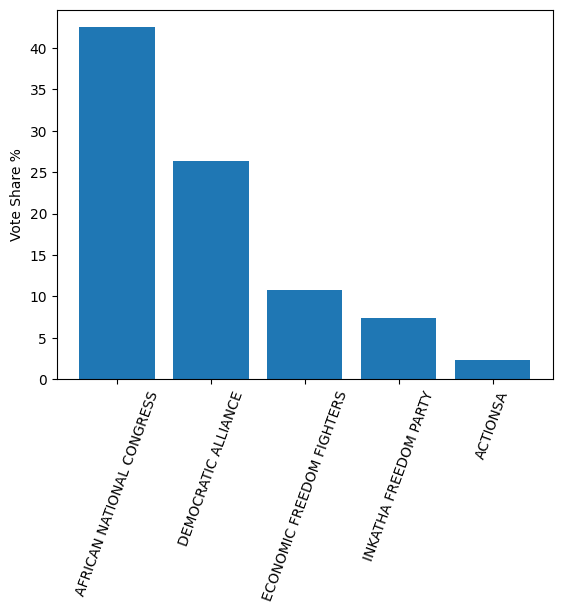

In [86]:
x=p[p["ElectionYear"]==2021].nlargest(5,"Share")
plt.bar(x["PartyName"],x["Share"])
plt.xticks(rotation=70)
plt.ylabel("Vote Share %")
plt.show()

### Interpretation

in 2021, ANC had the highest PR vote share in eThekwini,followed by the DA,EFF,IFP and ActionSA.This shows clear difference in party support and provides a baseline for later modelling

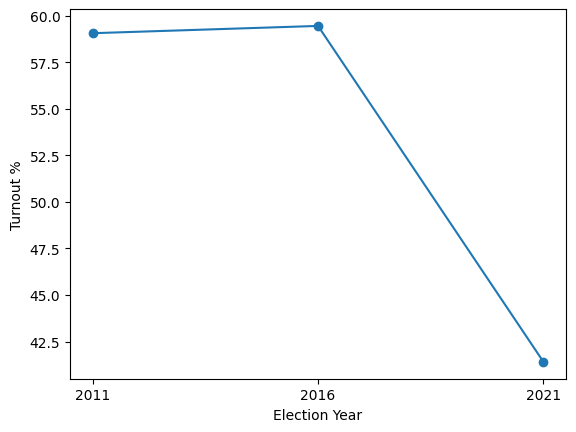

In [88]:
plt.plot(metro_turnout.index, metro_turnout["TurnoutRate"], marker="o")
plt.ylabel("Turnout %")
plt.xlabel("Election Year")
plt.xticks([2011, 2016, 2021])
plt.show()

In [89]:
w=ward_df.groupby(["ElectionYear","Ward","PartyName"])["TotalValidVotes"].sum().reset_index()
w["Share"]=w.groupby(["ElectionYear","Ward"])["TotalValidVotes"].transform(lambda x:x/x.sum()*100)
w["Winner"]=w.groupby(["ElectionYear","Ward"])["Share"].transform("max")==w["Share"]

In [90]:
w=w.sort_values(["Ward","PartyName","ElectionYear"])
w["PrevShare"]=w.groupby(["Ward","PartyName"])["Share"].shift()
m=w.dropna()

In [91]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

train=m[m.ElectionYear<2021]
test=m[m.ElectionYear==2021]

model=DecisionTreeClassifier(max_depth=4,random_state=1)
model.fit(train[["PrevShare"]],train["Winner"])

pred=model.predict(test[["PrevShare"]])
accuracy_score(test["Winner"],pred)

0.9764453961456103

In [92]:
r=test.copy()
r["Pred"]=pred
r=r[r.Pred==True]
r[["Ward","PartyName","PrevShare"]].head(3)

,Ward,PartyName,PrevShare
3701,Ward 59500002,AFRICAN NATIONAL CONGRESS,88.569446
3812,Ward 59500005,AFRICAN NATIONAL CONGRESS,81.067178
3850,Ward 59500006,AFRICAN NATIONAL CONGRESS,82.747905


In [93]:
from sklearn.linear_model import LinearRegression

top=p[p.ElectionYear==2021].nlargest(5,"Share")["PartyName"]

for party in top:
    a=p[p.PartyName==party]
    if len(a)>=2:
        model2=LinearRegression().fit(a[["ElectionYear"]],a["Share"])
        print(party,round(model2.predict([[2026]])[0],2))

AFRICAN NATIONAL CONGRESS 35.03
DEMOCRATIC ALLIANCE 25.12
ECONOMIC FREEDOM FIGHTERS 17.98
INKATHA FREEDOM PARTY 8.72


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [95]:
turnout_df = metro_turnout.reset_index()
tmodel = LinearRegression().fit(turnout_df[["ElectionYear"]], turnout_df["TurnoutRate"])
round(tmodel.predict([[2026]])[0], 2)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


np.float64(35.65)

In [ ]:
df_all.to_csv("eThekwini_combined_clean.csv",index=False)

In [96]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

rf=RandomForestClassifier(n_estimators=100,random_state=1)
rf.fit(train[["PrevShare"]],train["Winner"])
p2=rf.predict(test[["PrevShare"]])

for name,y in [("Tree",pred),("Forest",p2)]:
 print(name,
       "Acc",round(accuracy_score(test.Winner,y),2),
       "Prec",round(precision_score(test.Winner,y,zero_division=0),2),
       "Recall",round(recall_score(test.Winner,y,zero_division=0),2),
       "F1",round(f1_score(test.Winner,y,zero_division=0),2))

Tree Acc 0.98 Prec 0.9 Recall 0.67 F1 0.77
Forest Acc 0.98 Prec 0.88 Recall 0.69 F1 0.78


In [98]:
from sklearn.metrics import confusion_matrix
confusion_matrix(test["Winner"], p2)

array([[1748,   10],
       [  34,   76]])

In [100]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

y = turnout_df["TurnoutRate"]
yp = cross_val_predict(LinearRegression(), turnout_df[["ElectionYear"]], y, cv=LeaveOneOut())

print("MAE:", round(mean_absolute_error(y, yp), 2))
print("RMSE:", round(mean_squared_error(y, yp)**0.5, 2))

MAE: 15.36
RMSE: 15.97


## Model Evaluation

compared decisionm and random forest

In [103]:
!pip install -q streamlit
import streamlit as st
import pandas as pd

# Ensure the dataset file exists locally before Streamlit attempts to read it
df_all.to_csv("eThekwini_combined_clean.csv", index=False)

st.title("eThekwini Election Analytics 2026")

df=pd.read_csv("eThekwini_combined_clean.csv")

st.subheader("Historical Election Data")
st.dataframe(df.head())

st.subheader("2021 Top Parties")
p=df[(df["ElectionYear"]==2021)&(df["BallotType"]=="PR")]
p=p.groupby("PartyName")["TotalValidVotes"].sum().nlargest(5)
st.bar_chart(p)

st.subheader("Important Note")
st.write("2026 outputs are model estimates, not known election results.")

2026-10-05 13:04:18.236 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 13:04:18.236 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 13:04:18.238 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 13:04:18.541 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 13:04:18.542 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 13:04:18.543 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 13:04:18.591 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 13:04:18.592 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [104]:
from google.colab import files
files.download("eThekwini_combined_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>